# 🤖 Name That LLM: Kaun se LLM ne ye passage likha?

### 🎯 Project ka goal
Ek passage (text) diya jaata hai aur humein batana hai ki **18 alag LLMs mein se kis ne likha**.
Ye ek **18-class classification** problem hai. Random guess ka accuracy sirf **~5.5%** hota hai, isliye usse upar jo bhi score aaye wo model ki asli seekh hai.

### 📂 Dataset
- File: `passages_clean.csv` (5070 passages, 296 prompts, 18 LLMs)
- **Target:** `model` column (kis LLM ne likha)
- **Text:** `text` column (passage)
- **Group:** `prompt_id` (same prompt ke saare jawab ek hi side mein rakhne ke liye)

### 🛠️ Pipeline (step by step)
| Step | Kya hoga |
|---|---|
| 1 | Libraries import aur data load |
| 2 | Target ka graph |
| 3 | Data cleaning (missing, duplicate, leakage columns) |
| 4 | Text se features banana (length, punctuation, em-dash, curly quotes, markdown) |
| 5 | LLM-wise writing style ka EDA |
| 6 | Train-test split (prompt_id ke hisaab se) aur scaling |
| 7 | 5 models ki training |
| 8 | Error analysis: TP, TN, FP, FN, confusion matrix, Accuracy, Precision, Recall, F1 |
| 9 | Models ka comparison aur overfitting check |
| 10 | Feature importance aur final conclusion |

### 🤝 5 Models (sirf wahi jo padhe hain aur is data par fit baithte hain)
Logistic Regression, Decision Tree, Random Forest, KNN, Gaussian Naive Bayes

### ⚠️ Leakage se bachav
Provider, tokens, cost, response id jaise columns se model ka naam seedha pata chal jata hai, isliye wo hata diye jaayenge. Model sirf `text` se bane features dekhega.

### ▶️ Kaise chalana hai
Notebook aur `passages_clean.csv` ek hi folder mein rakho, phir cells upar se neeche ek-ek karke chalao.

## 1. Libraries import karo
Pehle data aur graph wali libraries, phir sklearn ke models.

In [1]:
import pandas as pd  # pandas handles table-like data
import numpy as np  # numpy handles numbers and arrays
import matplotlib.pyplot as plt  # matplotlib draws graphs
import seaborn as sns  # seaborn makes prettier graphs
import warnings  # warnings module controls warning messages
warnings.filterwarnings('ignore')  # hide unnecessary warnings

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer  # turns words into numbers
from sklearn.linear_model import LogisticRegression  # model 1: Logistic Regression
from sklearn.tree import DecisionTreeClassifier  # model 2: Decision Tree
from sklearn.ensemble import RandomForestClassifier  # model 3: Random Forest
from sklearn.neighbors import KNeighborsClassifier  # model 4: KNN
from sklearn.naive_bayes import GaussianNB  # model 5: Gaussian Naive Bayes

## 2. Data load karo
CSV padho, target column ka naam badlo aur shape, info, describe dekho.

In [3]:
df = pd.read_csv('passages_clean.csv')  # load the passages file into a table

In [4]:
df = df.rename(columns={'model': 'label'})  # rename the 'model' column to 'label' (our target)
print(df.shape)  # print number of rows and columns

(5070, 42)


In [5]:
df.head(3)  # show the first 3 rows

,id,dataset_version_added,attempt,prompt_id,label,text,n_words,word_min,word_max,target_words,...,source_prompt_id,is_refusal,is_truncated,is_empty,has_markdown,in_word_range,passes_funnel,passes_funnel_regen,funnel_fail_step,max_shared_8grams_comp
0,n001__claude-fable-5__a0,1,0,n001,claude-fable-5,"When a pan is only moderately hot, a water dro...",99,40,250,95.0,...,NaN,False,False,False,False,True,True,True,NaN,0
1,n001__claude-opus-4-6__a0,1,0,n001,claude-opus-4-6,"When a water drop lands on a merely warm pan, ...",97,40,250,83.0,...,NaN,False,False,False,False,True,True,True,NaN,0
2,n001__claude-opus-4-8__a0,1,0,n001,claude-opus-4-8,"When a water drop hits a very hot pan, its und...",56,40,250,47.0,...,NaN,False,False,False,False,True,True,True,NaN,0


In [6]:
df.columns

Index(['id', 'dataset_version_added', 'attempt', 'prompt_id', 'label', 'text',
       'n_words', 'word_min', 'word_max', 'target_words', 'prompt_sent',
       'domain', 'task_type', 'topic', 'style', 'opening_phrase', 'split',
       'provider_route', 'requested_model_id', 'served_model_id',
       'served_provider', 'generated_at_utc', 'reasoning_setting',
       'finish_reason', 'finish_reason_norm', 'input_tokens', 'output_tokens',
       'reasoning_tokens', 'cost_usd', 'call_id', 'response_id',
       'n_calls_for_cell', 'source_prompt_id', 'is_refusal', 'is_truncated',
       'is_empty', 'has_markdown', 'in_word_range', 'passes_funnel',
       'passes_funnel_regen', 'funnel_fail_step', 'max_shared_8grams_comp'],
      dtype='str')

In [7]:
df.info()  # show column types and non-null counts

<class 'pandas.DataFrame'>
RangeIndex: 5070 entries, 0 to 5069
Data columns (total 42 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      5070 non-null   str    
 1   dataset_version_added   5070 non-null   int64  
 2   attempt                 5070 non-null   int64  
 3   prompt_id               5070 non-null   str    
 4   label                   5070 non-null   str    
 5   text                    5070 non-null   str    
 6   n_words                 5070 non-null   int64  
 7   word_min                5070 non-null   int64  
 8   word_max                5070 non-null   int64  
 9   target_words            5070 non-null   float64
 10  prompt_sent             5070 non-null   str    
 11  domain                  5070 non-null   str    
 12  task_type               5070 non-null   str    
 13  topic                   5070 non-null   str    
 14  style                   4926 non-null   str    
 15

In [8]:
df.describe()  # show summary statistics of numeric columns

,dataset_version_added,attempt,n_words,word_min,word_max,target_words,input_tokens,output_tokens,reasoning_tokens,cost_usd,n_calls_for_cell,max_shared_8grams_comp
count,5070.000000,5070.000000,5070.000000,5070.0,5070.0,5070.000000,5070.000000,5070.000000,4659.000000,5070.000000,5070.000000,5070.000000
mean,1.386982,0.000197,113.763905,40.0,250.0,112.951282,76.435503,1322.642998,1256.981112,0.011930,1.000197,0.017357
std,0.944373,0.014044,56.613502,0.0,0.0,56.590619,26.242170,1597.243101,1623.966657,0.014108,0.014044,0.244277
min,1.000000,0.000000,40.000000,40.0,250.0,40.000000,33.000000,49.000000,0.000000,0.000131,1.000000,0.000000
25%,1.000000,0.000000,65.000000,40.0,250.0,64.250000,58.000000,258.000000,64.000000,0.003637,1.000000,0.000000
50%,1.000000,0.000000,100.000000,40.0,250.0,99.000000,69.000000,596.500000,575.000000,0.007800,1.000000,0.000000
75%,1.000000,0.000000,155.750000,40.0,250.0,155.000000,89.000000,1818.250000,1882.000000,0.014946,1.000000,0.000000
max,5.000000,1.000000,250.000000,40.0,250.0,250.000000,171.000000,11367.000000,11185.000000,0.123998,2.000000,7.000000


## 3. Target ka graph
Dekho har LLM ke kitne passages hain (data balanced hai ya nahi).

In [9]:
cnt = df['label'].value_counts()  # count passages for each LLM
print(cnt)  # print the counts

label
claude-opus-4-6           296
claude-opus-4-8           296
claude-opus-5             296
claude-sonnet-5           296
gemini-3.1-pro-preview    296
gemini-3.6-flash          296
gemini-3.8-flash          296
gpt-5.5                   296
gpt-5.6-luna              296
gpt-5.6-sol               296
gpt-5.6-terra             296
gpt-6-astra               296
claude-fable-5            253
gemini-3.7-flash          253
glm-5.3                   253
glm-5.3-flash             253
kimi-k3                   253
qwen3.8-max               253
Name: count, dtype: int64


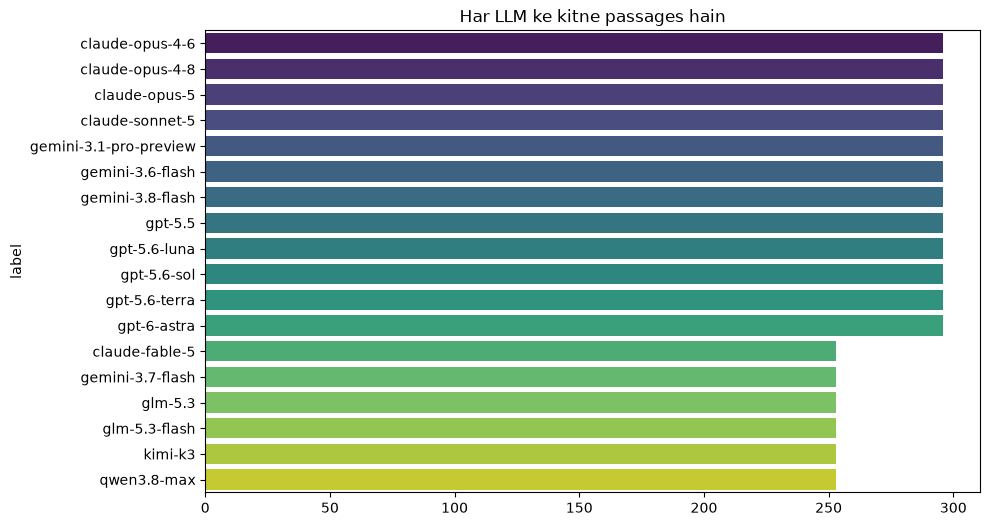

In [10]:
plt.figure(figsize=(10, 6))  # graph ka size set karo
sns.barplot(x=cnt.values, y=cnt.index, palette='viridis')  # har LLM ke passages ka bar chart banao
plt.title('Har LLM ke kitne passages hain')  # graph ka title lagao
plt.show()  # graph dikhao
# INSIGHT: 12 LLMs ke 296 aur 6 LLMs ke 253 passages hain, yaani data lagbhag balanced hai
# INSIGHT: 18 classes hain, toh random guess ka accuracy sirf ~5.5% hota hai

## 4. Data cleaning
Missing values, khali text, duplicates aur **leakage wale columns** hatao.

In [11]:
df.isnull().sum().head(10)    # check missing values in the first 10 columns

id                       0
dataset_version_added    0
attempt                  0
prompt_id                0
label                    0
text                     0
n_words                  0
word_min                 0
word_max                 0
target_words             0
dtype: int64

In [12]:
df = df.dropna(subset=['text', 'label', 'prompt_id'])  # drop rows missing text, label or prompt_id
df = df[df['text'].str.strip() != '']  # drop rows where the text is empty
print(df.shape)  # print the shape after dropping

(5070, 42)


In [13]:
print(df.duplicated(subset=['text']).sum())  # count repeated passages
df = df.drop_duplicates(subset=['text'])  # remove repeated passages

0


In [14]:
df = df.drop(columns=['id', 'dataset_version_added', 'attempt', 'n_words', 'word_min', 'word_max', 'target_words', 'prompt_sent', 'provider_route', 'requested_model_id',
'served_model_id', 'served_provider', 'generated_at_utc', 'reasoning_setting', 'finish_reason', 'finish_reason_norm', 'input_tokens', 'output_tokens', 'reasoning_tokens', 
'cost_usd', 'call_id', 'response_id', 'n_calls_for_cell', 'source_prompt_id', 'passes_funnel', 'passes_funnel_regen', 'funnel_fail_step', 'max_shared_8grams_comp'], 
errors='ignore')  # drop leakage columns (provider, tokens, cost reveal the model name)

df = df.reset_index(drop=True)  # reset the row numbers from 0
print(df.shape)  # print the cleaned shape

(5070, 14)


## 5. Text ko numbers mein badlo (feature engineering)
Har LLM ka likhne ka style alag hota hai (lambai, punctuation, markdown, em-dash, curly quotes). Wahi numbers features banenge.

In [15]:
df['len'] = df['text'].str.len()  # number of characters in the passage
df['words'] = df['text'].str.split().str.len()  # number of words in the passage
df['lines'] = df['text'].str.count('\n')  # number of new lines
df['upper'] = df['text'].str.count(r'[A-Z]')  # number of capital letters
df['digits'] = df['text'].str.count(r'\d')  # number of digits

In [16]:
df['commas'] = df['text'].str.count(',')  # number of commas
df['dots'] = df['text'].str.count(r'\.')  # number of full stops
df['qmark'] = df['text'].str.count(r'\?')  # number of question marks
df['excl'] = df['text'].str.count('!')  # number of exclamation marks
df['colon'] = df['text'].str.count(':')  # number of colons
df['semi'] = df['text'].str.count(';')  # number of semicolons

In [17]:
df['star'] = df['text'].str.count(r'\*')  # number of * (markdown bold)
df['hash'] = df['text'].str.count('#')  # number of # (markdown heading)
df['dash'] = df['text'].str.count('-')  # number of dashes (bullet points)
df['quote'] = df['text'].str.count('"')  # number of straight double quotes

In [18]:
df['emdash'] = df['text'].str.count('—')  # number of em-dashes (Claude, GLM, Kimi use more)
df['curlyq'] = df['text'].str.count('[“”]')  # number of curly double quotes (GPT, Gemini use more)
df['curlya'] = df['text'].str.count('’')  # number of curly apostrophes (GPT, Gemini use more)

In [19]:
df['avgw'] = df['len'] / df['words']  # average word length
df['uniq'] = df['text'].str.lower().str.split().apply(set).str.len() / df['words']  # share of unique words (vocabulary richness)
df = df.replace([np.inf, -np.inf], 0).fillna(0)  # fix divide-by-zero and missing values

### Target ko number banao
LLM ke naam ko 0 se 17 tak ke number mein badlo, aur naam yaad rakho.

In [20]:
y = df['label'].astype('category').cat.codes  # LLM ke naam ko 0 se 17 tak ke number mein badlo (target)
names = df['label'].astype('category').cat.categories  # yaad rakho kaun sa number kis LLM ka hai
print(names)  # LLM ke naam print karo

Index(['claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5',
       'claude-sonnet-5', 'gemini-3.1-pro-preview', 'gemini-3.6-flash',
       'gemini-3.7-flash', 'gemini-3.8-flash', 'glm-5.3', 'glm-5.3-flash',
       'gpt-5.5', 'gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra',
       'gpt-6-astra', 'kimi-k3', 'qwen3.8-max'],
      dtype='str')


In [21]:
df['emdash'] = df['text'].str.count('\u2014')  # passage mein em-dash (—) kitni baar aaya
df['curlyq'] = df['text'].str.count('\u201c|\u201d')  # passage mein curly quotes (“ ”) kitni baar aaye
df['curlya'] = df['text'].str.count('\u2019')  # passage mein curly apostrophe (’) kitni baar aaya

In [22]:
print(df[['emdash', 'curlyq', 'curlya']].sum())  # teeno ka total dekho, 0 nahi aana chahiye

emdash    4183
curlyq     896
curlya    2173
dtype: int64


In [23]:
X0 = df[['len', 'words', 'lines', 'upper', 'digits', 'commas', 'dots', 'qmark', 'excl', 'colon', 'semi', 'star', 'hash', 'dash', 'quote', 'emdash', 'curlyq', 'curlya', 'avgw', 'uniq']]  # keep ONLY text-based features (no metadata, avoids leakage)
X0 = pd.get_dummies(X0)  # apply get_dummies (all features are numeric so nothing changes, safe step)
print(X0.shape)  # print the feature table shape

(5070, 20)


## 6. LLM-wise writing style (EDA)
Har LLM ke features ka average dekho. Jahan numbers alag-alag hain, wahi feature model ke kaam ka hai.

In [24]:
g = df.groupby('label')[['words', 'lines', 'emdash', 'curlyq', 'curlya', 'semi', 'star', 'hash', 'dash', 'uniq']].mean().round(2)  # average style features for each LLM
print(g)  # print the table

                         words  lines  emdash  curlyq  curlya  semi  star  \
label                                                                       
claude-fable-5          113.90   0.05    1.58    0.00    0.00  0.35  0.12   
claude-opus-4-6         115.82   0.00    1.35    0.00    0.00  0.15  0.26   
claude-opus-4-8         109.78   0.01    1.08    0.00    0.00  0.24  0.19   
claude-opus-5           115.88   0.09    1.30    0.00    0.00  0.50  0.28   
claude-sonnet-5         121.41   0.05    1.40    0.00    0.02  0.23  0.07   
gemini-3.1-pro-preview  116.23   0.10    0.22    0.03    0.46  0.19  0.09   
gemini-3.6-flash        107.58   0.07    0.31    0.01    0.46  0.23  0.06   
gemini-3.7-flash        110.29   0.06    0.40    0.03    0.57  0.30  0.08   
gemini-3.8-flash        111.19   0.11    0.35    0.03    0.61  0.32  0.11   
glm-5.3                 114.15   0.13    1.64    0.00    0.00  0.60  0.06   
glm-5.3-flash           109.76   0.00    1.62    0.00    0.00  0.53  0.07   

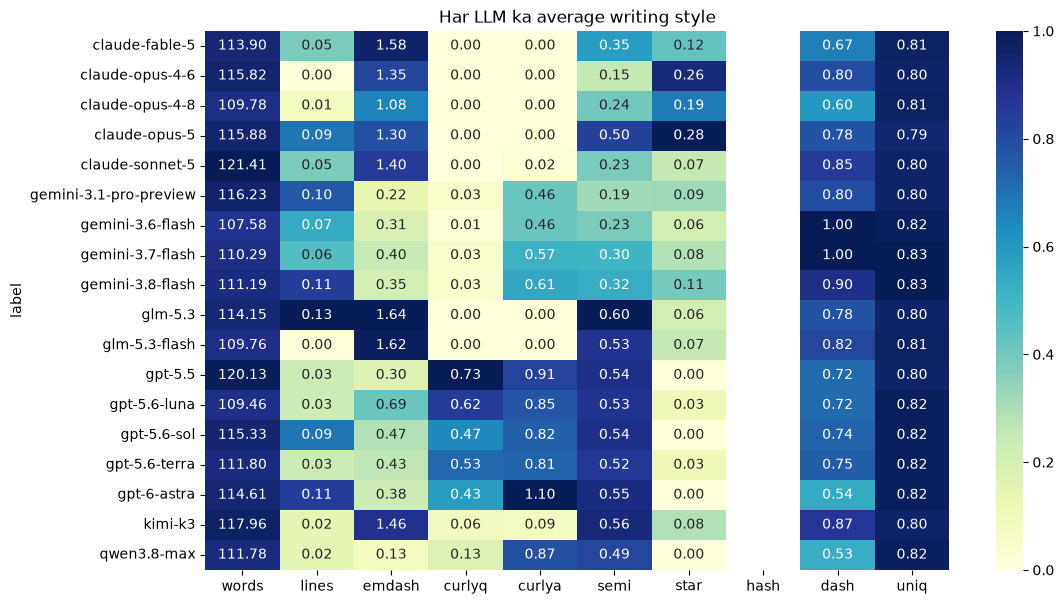

In [25]:
plt.figure(figsize=(12, 7))  # graph ka size set karo
sns.heatmap(g / g.max(), annot=g, fmt='.2f', cmap='YlGnBu')  # rang 0-1 scale par, andar asli number dikhao
plt.title('Har LLM ka average writing style')  # graph ka title lagao
plt.show()  # graph dikhao
# INSIGHT: jis column mein LLMs ke numbers alag-alag hain, wahi feature model ke kaam ka hai
# INSIGHT: jin LLMs ki row lagbhag same hai, wo aapas mein confuse honge

## 7. Train-test split (prompt_id ke hisaab se)
Same prompt ke jawab train aur test dono mein gaye toh score jhootha aayega. Isliye **prompts** ko 80/20 baantenge.

In [26]:
ids = pd.Series(df['prompt_id'].unique())  # saare alag prompt id nikalo aur Series bana lo
te_ids = ids.sample(frac=0.2, random_state=42)  # 20% prompts random chuno (random_state se har baar same aayenge)
m = df['prompt_id'].isin(te_ids)  # jis row ka prompt test wala hai wahan True, baaki False

In [27]:
X_tr = X0[~m]  # train ke features (80% prompts)
X_te = X0[m]  # test ke features (20% prompts)
y_tr = y[~m]  # train ka target
y_te = y[m]  # test ka target
print(X_tr.shape, X_te.shape)  # train aur test dono ka shape print karo

(4044, 20) (1026, 20)


### Top 200 words (TF-IDF)
Sirf train text se seekhenge, taaki test ki jaankari leak na ho.

In [28]:
tf = TfidfVectorizer(max_features=200)  # Sirf 200 sabse important words select karega

T_tr = tf.fit_transform(df.loc[~m, 'text'])  # Training text se words seekhega aur unhe numbers mein convert karega

T_te = tf.transform(df.loc[m, 'text'])  # Test text ko training wale same words se numbers mein convert karega

col = 'w_' + pd.Series(tf.get_feature_names_out())  # Har selected word ke aage w_ lagakar column names banayega

In [29]:
# Train ke TF-IDF numbers (sparse format) ko normal table banao, columns ke naam w_word jaise
T_tr = pd.DataFrame(T_tr.toarray(), index=X_tr.index, columns=col.values)

# Test ke TF-IDF numbers ko bhi table banao (same columns, same vocabulary)
T_te = pd.DataFrame(T_te.toarray(), index=X_te.index, columns=col.values)

# Train: style features (length, bullets etc.) aur word features ko side by side jodo
X_tr = pd.concat([X_tr, T_tr], axis=1)

# Test: same jodna, taaki train aur test ke columns barabar rahein
X_te = pd.concat([X_te, T_te], axis=1)

# Final shape check: (rows, columns). Dono mein columns ki sankhya same honi chahiye
print(X_tr.shape, X_te.shape)

(4044, 220) (1026, 220)


### Scaling (sirf Logistic Regression aur KNN ke liye)
Pandas se: `(value - average) / std`, aur average/std sirf train se lenge.

In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Train se seekho (average aur spread nikalo) aur train ko scale karo
X_tr_s = scaler.fit_transform(X_tr)

# Test ko sirf transform karo, train ke hi average/spread se
X_te_s = scaler.transform(X_te)

## 8. Model training (5 models)
- **Logistic Regression:** 18 classes ke liye natural baseline (scaled data)
- **Decision Tree:** simple if-else rules, samajhne mein aasan
- **Random Forest:** kai trees ka average, overfitting kam, feature importance deta hai
- **KNN:** sabse milte-julte passages dekhke batata hai (scaled data)
- **Gaussian Naive Bayes:** tez probability wala model

**Use nahi kiye:** Linear Regression (number predict karta hai, LLM ka naam nahi) aur K-Means / Hierarchical Clustering (bina label ke group banate hain, accuracy nikal hi nahi sakti).

In [31]:
lr = LogisticRegression(max_iter=1000)  # Logistic Regression model banao (max_iter=1000 matlab 1000 baar tak seekhne ki koshish karega)
lr.fit(X_tr_s, y_tr)  # scaled train data par model ko train karo (Logistic Regression ko scaling pasand hai)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [32]:
dt = DecisionTreeClassifier(max_depth=10, random_state=42)  # Decision Tree banao (depth 10 tak limit, taaki overfitting na ho)
dt.fit(X_tr, y_tr)  # train data par Decision Tree ko train karo (isko scaling ki zaroorat nahi hoti)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at

In [33]:
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)  # Random Forest banao (200 trees, har tree alag-alag data se seekhta hai, n_jobs=-1 matlab saare CPU cores use karo taaki tez chale)
rf.fit(X_tr, y_tr)  # train data par model ko train karo (Decision Tree ki tarah isko bhi scaling ki zaroorat nahi hoti)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [34]:
kn = KNeighborsClassifier(n_neighbors=5)  # KNN banao (har naye passage ke liye 5 sabse paas wale passages dekhega aur unka vote lega)
kn.fit(X_tr_s, y_tr)  # scaled train data store karo (KNN sirf data yaad rakhta hai, seekhta nahi; distance nikalne ke liye scaling zaroori hai)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int8](18,)","[ 0, 1, 2,...,15,16,17]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [35]:
nb = GaussianNB()  # Gaussian Naive Bayes banao (probability ke basis par kaam karta hai, bahut tez hota hai)
nb.fit(X_tr, y_tr)  # train data par model ko train karo (isko scaling ki zaroorat nahi hoti)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](18,)","[200.,237.,237.,...,237.,200.,200.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](18,)","[0.05,0.06,0.06,...,0.06,0.05,0.05]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int8](18,)","[ 0, 1, 2,...,15,16,17]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.0001199
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](220,)","['len','words','lines',...,'w_yet','w_you','w_your']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,220
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](18, 220)","[[705.31,114.08, 0.06,..., 0.02, 0.08, 0.05], [705.35,113.03, 0. ,..., 0.03, 0.08, 0.06], [677.38,111.11, 0.02,..., 0.02, 0.1 , 0.07], ..., [726.49,114.24, 0.11,..., 0.02, 0.08, 0.05], [721.52,118.79, 0.03,..., 0.02, 0.08, 0.05], [659.45,108.31, 0.02,..., 0.02, 0.07, 0.04]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](18, 220)","[[104254.36, 2890.31, 0.2 ,..., 0. , 0.03, 0.02], [109759.54, 3035.16, 0. ,..., 0. , 0.02, 0.02], [120326.25, 3350.05, 0.07,..., 0. , 0.03, 0.02], ..., [145753.07, 3626.02, 0.78,..., 0. , 0.03, 0.02], [123531.85, 3530.95, 0.1 ,..., 0. , 0.02, 0.02], [103790.04, 3073.42, 0.08,..., 0. , 0.02, 0.01]]"


### Predictions (train aur test dono par)

In [36]:
lr_tr = lr.predict(X_tr_s)  # Logistic Regression predictions on train
lr_te = lr.predict(X_te_s)  # Logistic Regression predictions on test

In [37]:
dt_tr = dt.predict(X_tr)  # Decision Tree predictions on train
dt_te = dt.predict(X_te)  # Decision Tree predictions on test

In [38]:
rf_tr = rf.predict(X_tr)  # Random Forest predictions on train
rf_te = rf.predict(X_te)  # Random Forest predictions on test

In [39]:
kn_tr = kn.predict(X_tr_s)  # KNN predictions on train
kn_te = kn.predict(X_te_s)  # KNN predictions on test

In [40]:
nb_tr = nb.predict(X_tr)  # Naive Bayes predictions on train
nb_te = nb.predict(X_te)  # Naive Bayes predictions on test

## 9. Error analysis (har model ke liye train aur test)
Har cell mein: confusion matrix, **TP, TN, FP, FN**, **Accuracy, Precision, Recall, F1** (macro, yaani sab LLMs ka average). Sab numpy aur pandas se nikala hai.

In [41]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix  # metrics ke functions

res = []  # saare models ke scores yahan jama honge (baad mein comparison table banega)

def scores(name, y_true, y_pred):  # ek function jo ek model ke saare scores nikalega
    cm = confusion_matrix(y_true, y_pred, labels=range(len(names)))  # confusion matrix banao
    tp = int(np.diag(cm).sum())  # TP: sahi predictions (int() se np.int64 hat jayega)
    fp = fn = int(cm.sum()) - tp  # FP aur FN: galat predictions (multiclass mein dono barabar)
    tn = (len(names) - 2) * int(cm.sum()) + tp  # TN: sab classes ka total
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=range(len(names)), average='macro', zero_division=0)  # macro precision, recall, F1
    acc = accuracy_score(y_true, y_pred)  # accuracy
    res.append({'Model': name, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn, 'Acc': round(acc, 3), 'Prec': round(p, 3), 'Rec': round(r, 3), 'F1': round(f, 3)})  # comparison ke liye save karo
    print(f'{name:<10} | TP {tp:>5} | FP {fp:>5} | FN {fn:>5} | TN {tn:>6} | Acc {acc:.3f} | Prec {p:.3f} | Rec {r:.3f} | F1 {f:.3f}')  # saaf aur seedhi line mein print karo

9.1 to 9.5: Har model ke scores

In [42]:
scores('LR train', y_tr, lr_tr)  # Logistic Regression ke train scores
scores('LR test', y_te, lr_te)  # Logistic Regression ke test scores

LR train   | TP  2158 | FP  1886 | FN  1886 | TN  66862 | Acc 0.534 | Prec 0.528 | Rec 0.528 | F1 0.526
LR test    | TP   286 | FP   740 | FN   740 | TN  16702 | Acc 0.279 | Prec 0.268 | Rec 0.275 | F1 0.268


### 9.2 Decision Tree

In [43]:
scores('DT train', y_tr, dt_tr)  # Decision Tree ke train scores
scores('DT test', y_te, dt_te)  # Decision Tree ke test scores

DT train   | TP  1643 | FP  2401 | FN  2401 | TN  66347 | Acc 0.406 | Prec 0.459 | Rec 0.403 | F1 0.406
DT test    | TP   149 | FP   877 | FN   877 | TN  16565 | Acc 0.145 | Prec 0.153 | Rec 0.144 | F1 0.137


### 9.3 Random Forest

In [44]:
scores('RF train', y_tr, rf_tr)  # Random Forest ke train scores
scores('RF test', y_te, rf_te)  # Random Forest ke test scores

RF train   | TP  4044 | FP     0 | FN     0 | TN  68748 | Acc 1.000 | Prec 1.000 | Rec 1.000 | F1 1.000
RF test    | TP   228 | FP   798 | FN   798 | TN  16644 | Acc 0.222 | Prec 0.199 | Rec 0.217 | F1 0.196


### 9.4 KNN

In [45]:
scores('KNN train', y_tr, kn_tr)  # KNN ke train scores
scores('KNN test', y_te, kn_te)  # KNN ke test scores

KNN train  | TP   921 | FP  3123 | FN  3123 | TN  65625 | Acc 0.228 | Prec 0.290 | Rec 0.227 | F1 0.192
KNN test   | TP   103 | FP   923 | FN   923 | TN  16519 | Acc 0.100 | Prec 0.109 | Rec 0.099 | F1 0.083


### 9.5 Gaussian Naive Bayes

In [46]:
scores('NB train', y_tr, nb_tr)  # Naive Bayes ke train scores
scores('NB test', y_te, nb_te)  # Naive Bayes ke test scores

NB train   | TP  1236 | FP  2808 | FN  2808 | TN  65940 | Acc 0.306 | Prec 0.320 | Rec 0.303 | F1 0.289
NB test    | TP   178 | FP   848 | FN   848 | TN  16594 | Acc 0.173 | Prec 0.162 | Rec 0.172 | F1 0.153


## 10. Models ka comparison aur overfitting check
Saare 5 models ke scores ek table mein. Train aur test accuracy ka **gap** bada ho to model **overfit** hai.

In [47]:
r = pd.DataFrame(res).drop_duplicates(subset='Model', keep='last')  # duplicate rows hatao, har model ka sirf aakhri score rakho
r['Type'] = r['Model'].str.split().str[1]  # train ya test alag column mein nikalo
r['Name'] = r['Model'].str.split().str[0]  # model ka naam alag column mein nikalo
cmp = r.pivot(index='Name', columns='Type', values=['Acc', 'F1'])  # train/test side by side
cmp.columns = [a + '_' + b for a, b in cmp.columns]  # column ke naam saaf karo (Acc_train, Acc_test...)
cmp['Gap'] = (cmp['Acc_train'] - cmp['Acc_test']).round(3)  # overfitting gap = train acc - test acc
cmp = cmp.sort_values('Acc_test', ascending=False)  # best test accuracy upar
print(cmp)  # table print karo
print('Random guess accuracy:', round(1 / len(names), 3))  # 18 classes ka random guess (~0.055)

      Acc_test  Acc_train  F1_test  F1_train    Gap
Name                                               
LR       0.279      0.534    0.268     0.526  0.255
RF       0.222      1.000    0.196     1.000  0.778
NB       0.173      0.306    0.153     0.289  0.133
DT       0.145      0.406    0.137     0.406  0.261
KNN      0.100      0.228    0.083     0.192  0.128
Random guess accuracy: 0.056


Graph (Train vs Test)

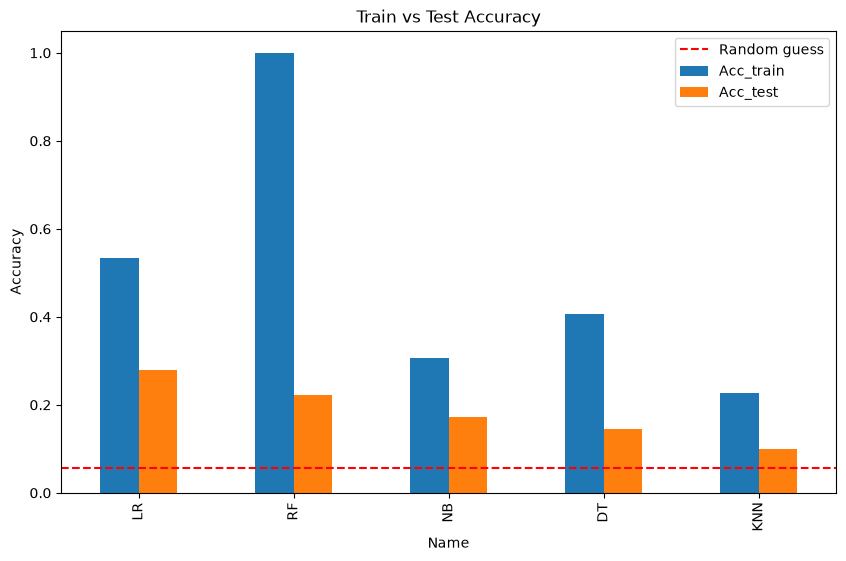

In [48]:
cmp[['Acc_train', 'Acc_test']].plot(kind='bar', figsize=(10, 6))  # train vs test accuracy ka bar chart
plt.axhline(1 / len(names), color='red', linestyle='--', label='Random guess')  # random guess ki red line
plt.title('Train vs Test Accuracy')  # graph ka title
plt.ylabel('Accuracy')  # y axis ka naam
plt.legend()  # legend dikhao
plt.show()  # graph dikhao
# INSIGHT: Random Forest ka train 100% hai par test 22%, yaani isne train data yaad kar liya (overfit)
# INSIGHT: saare bar red line se upar hain, yaani har model ne kuch na kuch asli seekha

### Best model ka confusion matrix
Dekho kaun sa LLM kis LLM se confuse ho raha hai. Diagonal jitna gehra, utna accha.

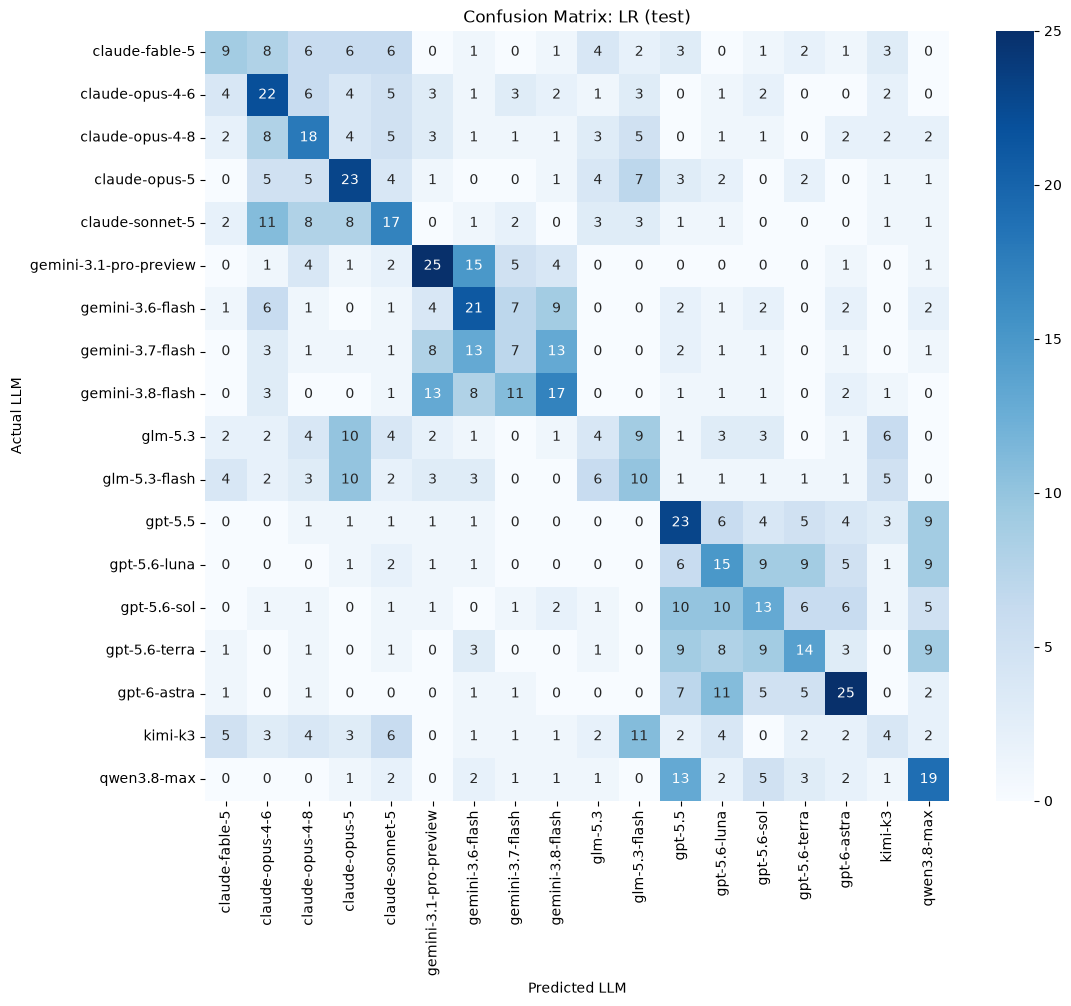

Best model: LR


In [49]:
best = cmp.index[0]  # test accuracy mein sabse upar wala model (LR)
pred = {'LR': lr_te, 'DT': dt_te, 'RF': rf_te, 'KNN': kn_te, 'NB': nb_te}[best]  # us model ki test predictions
cm = confusion_matrix(y_te, pred, labels=range(len(names)))  # confusion matrix banao
plt.figure(figsize=(12, 10))  # graph ka size
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=names, yticklabels=names)  # heatmap banao
plt.title('Confusion Matrix: ' + best + ' (test)')  # title
plt.xlabel('Predicted LLM')  # model ne kya bola
plt.ylabel('Actual LLM')  # asli LLM kaun tha
plt.show()  # graph dikhao
print('Best model:', best)  # best model ka naam print karo
# INSIGHT: ek hi family ke LLMs (jaise GPT-5.6 variants) aapas mein sabse zyada confuse honge

Har LLM ki pehchaan (recall)

glm-5.3                   0.075
kimi-k3                   0.075
gemini-3.7-flash          0.132
claude-fable-5            0.170
glm-5.3-flash             0.189
gpt-5.6-sol               0.220
gpt-5.6-terra             0.237
gpt-5.6-luna              0.254
gemini-3.8-flash          0.288
claude-sonnet-5           0.288
claude-opus-4-8           0.305
gemini-3.6-flash          0.356
qwen3.8-max               0.358
claude-opus-4-6           0.373
gpt-5.5                   0.390
claude-opus-5             0.390
gpt-6-astra               0.424
gemini-3.1-pro-preview    0.424
dtype: float64


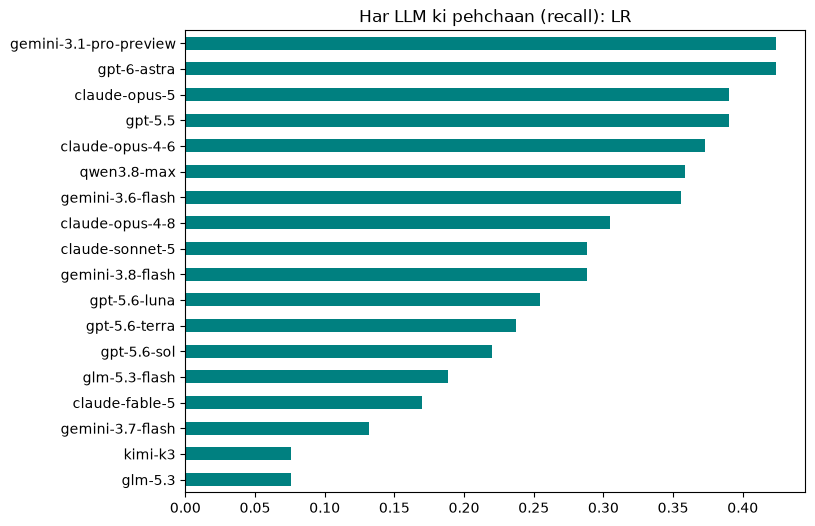

In [50]:
rec_each = pd.Series(np.diag(cm) / cm.sum(axis=1), index=names).sort_values()  # har LLM ko kitna sahi pehchana
print(rec_each.round(3))  # print karo
rec_each.plot(kind='barh', figsize=(8, 6), color='teal')  # bar chart
plt.title('Har LLM ki pehchaan (recall): ' + best)  # title
plt.show()  # dikhao
# INSIGHT: jo LLM upar hai (kam recall), uska style baaki LLMs se milta-julta hai
# INSIGHT: jo LLM neeche hai (zyada recall), uska style sabse alag hai

## 11. Feature importance
Random Forest batata hai ki **kaun sa feature** (em-dash, curly quotes, kaun sa word) LLM pehchanne mein sabse zyada kaam aaya.

avgw      0.0235
w_and     0.0217
w_of      0.0209
w_the     0.0203
uniq      0.0192
len       0.0181
emdash    0.0180
words     0.0169
w_in      0.0160
commas    0.0157
w_to      0.0154
curlya    0.0148
upper     0.0145
w_that    0.0139
dots      0.0135
dtype: float64


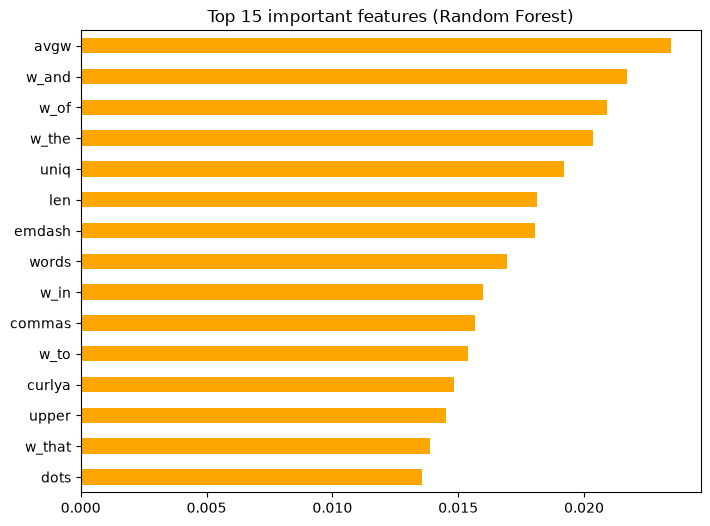

In [51]:
imp = pd.Series(rf.feature_importances_, index=X_tr.columns).sort_values(ascending=False)  # features ko importance ke hisaab se sort karo
print(imp.head(15).round(4))  # top 15 features print karo
imp.head(15).sort_values().plot(kind='barh', figsize=(8, 6), color='orange')  # top 15 ka bar chart
plt.title('Top 15 important features (Random Forest)')  # title
plt.show()  # dikhao
# INSIGHT: agar emdash, curlyq, curlya upar hain, to punctuation style hi LLM ki "fingerprint" hai
# INSIGHT: w_ se shuru hone wale features woh words hain jo TF-IDF se aaye

Style vs Words

In [52]:
style = imp[~imp.index.str.startswith('w_')].sum()  # style features ki total importance
words = imp[imp.index.str.startswith('w_')].sum()  # word features ki total importance
print('Style features:', round(style, 3), '| Word features:', round(words, 3))  # dono ka total
# INSIGHT: dekho style zyada kaam aaya ya words

Style features: 0.191 | Word features: 0.809


Final conclusion

## 12. Final Conclusion

- **Best model:** Logistic Regression, test accuracy **27.9%** (F1 0.268)
- **Random guess** sirf **5.6%** tha, yaani best model lagbhag **5 guna behtar** hai, isne asli pattern seekha
- **Sabse zyada overfit:** Random Forest (train 100%, test 22.2%, gap 0.778). Decision Tree ka gap 0.261 aur LR ka 0.255 hai
- **Sabse kamzor model:** KNN (test accuracy 10%)
- **Sabse important features:** ______ (cell 4 ka top 3 likho)
- **Style vs Words:** ______ zyada kaam aaya (cell 5 se)
- **Confuse hone wale LLMs:** ______ (confusion matrix se, jaise ek hi family ke models)
- **Limitation:** sirf 200 TF-IDF words aur 20 style features use hue, aur 18 LLMs mein se kai ek-dusre se bahut milte-julte hain
- **Aage kya:** DistilBERT jaise Hugging Face ke pretrained model se comparison (baseline vs transformer)